# Module 16 — Exercises — Solutions

These exercises rebuild a neural network layer by layer: activations and their derivatives, parameter and FLOP
counting, the stable softmax cross-entropy and its gradient, a `Dense` layer's backward pass with a gradient checker,
initialisation and variance propagation, batch normalisation, inverted dropout, a conceptual question on depth and
the He factor, convolution as a Toeplitz matrix, and a mini-project that trains a regularised digit classifier and
reports a bootstrap confidence interval. Only NumPy, SciPy and matplotlib are allowed — no PyTorch, no JAX. Data
matrices are `(n_samples, n_features)` and a layer computes `X @ W + b`. The concept guide (`README.md`) has every formula.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def central_diff(f, x, h=1e-6):
    # elementwise central difference of a vectorised scalar function f at the points x
    return (f(x + h) - f(x - h)) / (2 * h)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Activation functions and their derivatives  `★☆☆`

Implement `relu`, `softplus` and `gelu` and the derivatives `d_relu`, `d_sigmoid`, `d_tanh`, `d_softplus`, `d_gelu`
(all vectorised over NumPy arrays; `sigmoid` is given in the setup cell, and `erf` is imported from `scipy.special`):

$$
\mathrm{softplus}(z) = \ln(1 + e^z),\quad \mathrm{softplus}'(z) = \sigma(z); \qquad
\mathrm{GELU}(z) = z\,\Phi(z),\quad \mathrm{GELU}'(z) = \Phi(z) + z\,\varphi(z),
$$

with $\Phi(z) = \tfrac12\big(1 + \mathrm{erf}(z/\sqrt2)\big)$ the standard normal CDF and $\varphi(z) = e^{-z^2/2}/\sqrt{2\pi}$ its density.
`softplus` must not overflow for `z = 1000` (write it as $\max(z, 0) + \ln(1 + e^{-|z|})$). The checks compare every
derivative with central differences; two hidden checks ask for $\mathrm{GELU}(1.5)$ and $\mathrm{softplus}'(-3)$.

In [3]:
def relu(z):
    return np.maximum(z, 0.0)

def d_relu(z):
    return (np.asarray(z) > 0).astype(float)

def d_sigmoid(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def d_tanh(z):
    return 1.0 - np.tanh(z) ** 2

def softplus(z):
    return np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0.0)     # stable for large |z|

def d_softplus(z):
    return sigmoid(z)

def gelu(z):
    return z * 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

def d_gelu(z):
    Phi = 0.5 * (1.0 + erf(z / np.sqrt(2.0)))
    phi = np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)
    return Phi + z * phi

**Check your answer:**

In [4]:
zs = np.array([-3.0, -0.7, 0.2, 1.5, 4.0])
def _safe(fn, *a):
    try:
        out = fn(*a)
        return None if out is None else np.asarray(out, dtype=float)
    except Exception:
        return None
check_close('relu values', _safe(relu, zs), np.maximum(zs, 0))
check_close("relu' = 1[z > 0]", _safe(d_relu, zs), (zs > 0).astype(float))
check_close("sigmoid' vs central differences", _safe(d_sigmoid, zs), central_diff(sigmoid, zs), tol=1e-6)
check_close("tanh' vs central differences", _safe(d_tanh, zs), central_diff(np.tanh, zs), tol=1e-6)
sp = _safe(softplus, zs)
check_close('softplus values', sp, np.log1p(np.exp(zs)), tol=1e-9)
check('softplus(1000) is finite and equals 1000', (lambda v: v is not None and np.isfinite(v) and abs(float(v) - 1000.0) < 1e-9)(_safe(softplus, np.array(1000.0))))
check_close("softplus' vs central differences", _safe(d_softplus, zs), (central_diff(softplus, zs) if sp is not None else None), tol=1e-6)
ge = _safe(gelu, zs)
check_close('gelu(0) = 0 and gelu(4) ~ 4', _safe(gelu, np.array([0.0, 4.0])), np.array([0.0, 4.0 * 0.5 * (1 + erf(4.0 / np.sqrt(2)))]), tol=1e-9)
check_close("gelu' vs central differences", _safe(d_gelu, zs), (central_diff(gelu, zs) if ge is not None else None), tol=1e-6)
check_hash('hidden: GELU(1.5)', (float(ge[3]) if ge is not None else None), 'f03af073f3a641fa')
check_hash("hidden: softplus'(-3)", (float(_safe(d_softplus, np.array(-3.0))) if _safe(d_softplus, np.array(-3.0)) is not None else None), 'e5d3e87c0a26675a')

✅ relu values
✅ relu' = 1[z > 0]
✅ sigmoid' vs central differences
✅ tanh' vs central differences
✅ softplus values
✅ softplus(1000) is finite and equals 1000
✅ softplus' vs central differences
✅ gelu(0) = 0 and gelu(4) ~ 4
✅ gelu' vs central differences
✅ hidden: GELU(1.5)
✅ hidden: softplus'(-3)


True

**Why this works**

Each derivative is a one-line calculus exercise: $\sigma' = \sigma(1 - \sigma)$ by the quotient rule, $\tanh' = 1 - \tanh^2$,
$\mathrm{softplus}' = e^z/(1 + e^z) = \sigma(z)$, and $\mathrm{GELU}' = \Phi(z) + z\varphi(z)$ by the product rule (the derivative of
$\Phi$ is the density $\varphi$). The stable softplus form $\max(z, 0) + \ln(1 + e^{-|z|})$ is algebraically identical to
$\ln(1 + e^z)$ but never exponentiates a large positive number — the same trick as log-sum-exp. Note that `d_relu` must
cope with scalar inputs (`np.asarray`) and that at exactly $z = 0$ any value in $[0, 1]$ is a valid subgradient; the
convention `0` is what frameworks use.

## Exercise 2 — Parameter count, FLOPs and shapes  `★☆☆`

For an MLP with layer sizes `sizes = [n_in, h_1, ..., n_out]` implement

* `count_params(sizes)` — the total number of weights and biases, $\sum_l (n_l + 1)\, n_{l+1}$ (return an `int`);
* `forward_flops(sizes, batch_size)` — the FLOPs of all matrix products in one forward pass, counting each
  multiply-add as 2 FLOPs and ignoring biases and activations (an `int`);
* `forward_shapes(sizes, batch_size)` — the list of shapes `(batch_size, n_{l+1})` of $Z_1, \dots, Z_L$ as tuples.

Hidden checks: the parameter count of a 784 → 512 → 256 → 10 network, and the forward FLOPs of 64 → 128 → 10 at batch size 32.

In [5]:
def count_params(sizes):
    return int(sum((sizes[i] + 1) * sizes[i + 1] for i in range(len(sizes) - 1)))

def forward_flops(sizes, batch_size):
    return int(sum(2 * batch_size * sizes[i] * sizes[i + 1] for i in range(len(sizes) - 1)))

def forward_shapes(sizes, batch_size):
    return [(batch_size, s) for s in sizes[1:]]

**Check your answer:**

In [6]:
try:
    p_xor = count_params([2, 2, 1]); p_dig = count_params([64, 128, 10]); p_big = count_params([784, 512, 256, 10])
except Exception:
    p_xor = p_dig = p_big = None
check('2-2-1 XOR network has 9 parameters', p_xor == 9)
check('64-128-10 digit network has 9,610 parameters', p_dig == 9610)
check_hash('hidden: parameters of 784-512-256-10', p_big, 'ee542894ac5c53ad')
try:
    f_small = forward_flops([3, 2, 1], 2); f_dig = forward_flops([64, 128, 10], 32)
except Exception:
    f_small = f_dig = None
check('Section 3 example: 32 FLOPs for the two products', f_small == 32)
check_hash('hidden: forward FLOPs of 64-128-10 at batch 32', f_dig, 'caa1917fd26e0599')
try:
    shp = forward_shapes([64, 128, 10], 32)
    shp_ok = [tuple(s) for s in shp] == [(32, 128), (32, 10)]
except Exception:
    shp_ok = False
check('shapes of Z_1, Z_2 for 64-128-10 at batch 32', shp_ok)

✅ 2-2-1 XOR network has 9 parameters
✅ 64-128-10 digit network has 9,610 parameters
✅ hidden: parameters of 784-512-256-10
✅ Section 3 example: 32 FLOPs for the two products
✅ hidden: forward FLOPs of 64-128-10 at batch 32
✅ shapes of Z_1, Z_2 for 64-128-10 at batch 32


True

**Why this works**

A layer from $n_l$ to $n_{l+1}$ units has an $n_l \times n_{l+1}$ weight matrix plus $n_{l+1}$ biases, hence $(n_l + 1) n_{l+1}$
parameters; the matrix product $(B \times n_l)(n_l \times n_{l+1})$ costs $B\, n_l\, n_{l+1}$ multiply-adds, i.e. $2 B n_l n_{l+1}$ FLOPs.
Summed over layers this gives the rule of thumb "forward FLOPs ≈ 2 × weights × batch", and with the backward pass
(two products per layer) "training step ≈ 6 × weights × batch" — the estimate behind every compute budget for large
models. The shapes follow the rule $(B \times n_{\text{in}})(n_{\text{in}} \times n_{\text{out}}) = (B \times n_{\text{out}})$.

## Exercise 3 — Stable log-softmax and cross-entropy  `★☆☆`

Implement `log_softmax(Z)` for an $(n, k)$ logits matrix using the log-sum-exp trick,

$$
\ln P_{ij} = (Z_{ij} - m_i) - \ln \sum_c e^{Z_{ic} - m_i}, \qquad m_i = \max_c Z_{ic},
$$

and `cross_entropy(Z, y)` returning the mean of $-\ln P_{i, y_i}$ over the rows as a `float` (`y` is an integer array).
Both must survive logits such as 1000 and −1000 without `inf` or `nan`. The checks compare against
`scipy.special.log_softmax` and ask for the loss on a hidden logits matrix.

In [7]:
def log_softmax(Z):
    m = Z.max(axis=1, keepdims=True)
    return Z - m - np.log(np.sum(np.exp(Z - m), axis=1, keepdims=True))

def cross_entropy(Z, y):
    n = Z.shape[0]
    return float(-np.mean(log_softmax(Z)[np.arange(n), y]))

**Check your answer:**

In [8]:
from scipy.special import log_softmax as _sp_log_softmax
Z3 = np.array([[2.0, 0.0, -1.0], [0.0, 0.0, 0.0], [1000.0, 999.0, -1000.0], [-3.0, 4.0, 1.0], [0.5, 0.5, 5.0]])
y3 = np.array([0, 1, 1, 1, 2])
try:
    lp = log_softmax(Z3); lp = None if lp is None else np.asarray(lp, dtype=float)
except Exception:
    lp = None
check_close('log_softmax matches scipy.special.log_softmax (row-wise)', lp, _sp_log_softmax(Z3, axis=1), tol=1e-9)
check('finite for logits of +-1000', lp is not None and bool(np.all(np.isfinite(lp))))
check_close('rows exponentiate to probabilities summing to 1', (np.exp(lp).sum(axis=1) if lp is not None else None), np.ones(5), tol=1e-9)
try:
    ce = cross_entropy(Z3, y3); ce_uniform = cross_entropy(np.zeros((4, 10)), np.array([0, 3, 5, 9]))
except Exception:
    ce = ce_uniform = None
check_close('uniform logits over 10 classes give loss ln 10', ce_uniform, np.log(10), tol=1e-9)
check('cross_entropy returns a Python float', isinstance(ce, float))
check_hash('hidden: cross-entropy on the test logits', ce, '9ad30fe0a57d8ea7')

✅ log_softmax matches scipy.special.log_softmax (row-wise)
✅ finite for logits of +-1000
✅ rows exponentiate to probabilities summing to 1
✅ uniform logits over 10 classes give loss ln 10
✅ cross_entropy returns a Python float
✅ hidden: cross-entropy on the test logits


True

**Why this works**

Subtracting the row maximum leaves the softmax unchanged (it is invariant to adding a constant to every logit) but
makes every exponent $\le 0$, so `exp` never overflows and the largest term contributes exactly 1 to the sum, so the
logarithm is never of zero. The row `[1000, 999, -1000]` then gives $\ln P = (-0.313, -1.313, -2000.3)$ rather than
`nan`. Computing the loss from $\ln P$ directly — instead of `np.log(softmax(Z))` — is what `nn.CrossEntropyLoss` does,
and the uniform-logits check ($\ln k$) is the sanity test you should run on every classifier before training.

## Exercise 4 — The gradient of softmax cross-entropy  `★★☆`

Implement `softmax_ce_grad(Z, y)` returning $\partial \mathcal{L}/\partial Z = (P - Y)/n$ for the mean cross-entropy
of Exercise 3 ($Y$ is the one-hot matrix of `y`), and `sigmoid_mse_grad(z, y)` returning the elementwise derivative
of $(\sigma(z) - y)^2$ with respect to $z$, i.e. $2(\sigma(z) - y)\,\sigma(z)(1 - \sigma(z))$.

The checks verify the first against central differences of your `cross_entropy` and ask, as a hidden answer rounded
to one decimal, for the ratio of the cross-entropy gradient $\sigma(z) - y$ to the squared-error gradient at $z = -5$, $y = 1$.

In [9]:
def softmax_ce_grad(Z, y):
    n = Z.shape[0]
    P = np.exp(log_softmax(Z))
    P[np.arange(n), y] -= 1.0
    return P / n

def sigmoid_mse_grad(z, y):
    s = sigmoid(z)
    return 2.0 * (s - y) * s * (1.0 - s)

**Check your answer:**

In [10]:
try:
    G4 = softmax_ce_grad(Z3, y3); G4 = None if G4 is None else np.asarray(G4, dtype=float)
except Exception:
    G4 = None
check('gradient has the shape of Z', G4 is not None and G4.shape == Z3.shape)
check_close('gradient rows sum to zero', (G4.sum(axis=1) if G4 is not None else None), np.zeros(5), tol=1e-9)
def _num_grad(Z, y, h=1e-6):
    g = np.zeros_like(Z)
    for idx in np.ndindex(Z.shape):
        Zp = Z.copy(); Zp[idx] += h; Zm = Z.copy(); Zm[idx] -= h
        g[idx] = (cross_entropy(Zp, y) - cross_entropy(Zm, y)) / (2 * h)
    return g
try:
    Zr = rng.normal(size=(6, 4)) * 2; yr = rng.integers(0, 4, size=6)
    ng = _num_grad(Zr, yr); ag = np.asarray(softmax_ce_grad(Zr, yr), dtype=float)
except Exception:
    ng = ag = None
check_close('(P - Y)/n matches central differences of cross_entropy', ag, ng, tol=1e-6)
check_hash('hidden: sum |gradient| on the test logits', (float(np.abs(G4).sum()) if G4 is not None else None), '3d719c7957a8a263')
try:
    ratio = float((sigmoid(-5.0) - 1.0) / sigmoid_mse_grad(-5.0, 1.0))
    mse0 = float(sigmoid_mse_grad(0.0, 1.0))
except Exception:
    ratio = mse0 = None
check_close('sigmoid-MSE gradient at z = 0, y = 1 is -0.25', mse0, -0.25)
check_hash('hidden: CE/MSE gradient ratio at z = -5 (1 decimal)', ratio, '8db5dccea6502496', decimals=1)

✅ gradient has the shape of Z
✅ gradient rows sum to zero
✅ (P - Y)/n matches central differences of cross_entropy
✅ hidden: sum |gradient| on the test logits
✅ sigmoid-MSE gradient at z = 0, y = 1 is -0.25
✅ hidden: CE/MSE gradient ratio at z = -5 (1 decimal)


True

**Why this works**

With $\ln P_j = z_j - \mathrm{LSE}(z)$ and $\partial\,\mathrm{LSE}/\partial z_m = P_m$, the derivative of $-\sum_j Y_j \ln P_j$ with respect to
$z_m$ is $-Y_m + P_m$; the mean over rows contributes the $1/n$. Each row of the gradient sums to zero because the
softmax ignores a constant shift of the logits. The squared-error gradient carries the extra factor $\sigma(1 - \sigma)$,
which is $0.0066$ at $z = -5$: the model is confidently wrong and learns 75 times more slowly than with cross-entropy.
A common wrong turn is to forget the `/ n` (the checks against central differences of the *mean* loss catch it) or to
build the softmax Jacobian explicitly — correct, but $k$ times more work for the same answer.

## Exercise 5 — `Dense.backward` and a gradient checker  `★★☆`

Complete `Dense.backward(G)`: given $G = \partial\mathcal{L}/\partial Z$ for $Z = XW + \mathbf 1 b^\top$, store
$\partial\mathcal{L}/\partial W = X^\top G$ in `self.dW` and $\partial\mathcal{L}/\partial b = \sum_{\text{rows}} G$ in `self.db`, and return
$\partial\mathcal{L}/\partial X = G W^\top$. `ReLU` and `MLP` are given.

Then write `grad_check(model, loss_fn, Xb, yb, h=1e-5)`: run `model.forward`, `loss_fn` (which returns `(loss, dL/dZ)`)
and `model.backward` once, flatten the analytic gradients `model.grads()` in order, estimate every parameter entry
by central differences (perturb `p[idx]` in place, evaluate the loss, restore), and return the relative error
$\lVert g - \hat g\rVert / (\lVert g\rVert + \lVert \hat g\rVert)$ as a float. The hidden check is $\partial\mathcal{L}/\partial W_1$ for the concept guide's
Section 5 example.

In [11]:
class Dense:
    def __init__(self, n_in, n_out, scale=None, rng=rng):
        scale = np.sqrt(2.0 / n_in) if scale is None else scale
        self.W = rng.normal(0.0, scale, size=(n_in, n_out))
        self.b = np.zeros(n_out)
        self.dW = np.zeros_like(self.W); self.db = np.zeros_like(self.b)
    def forward(self, X):
        self.X = X
        return X @ self.W + self.b

    def backward(self, G):
        self.dW = self.X.T @ G
        self.db = G.sum(axis=0)
        return G @ self.W.T

    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]

class ReLU:
    def forward(self, Z):
        self.mask = Z > 0
        return Z * self.mask
    def backward(self, G): return G * self.mask
    def params(self): return []
    def grads(self):  return []

class MLP:
    def __init__(self, layers): self.layers = layers
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X
    def backward(self, G):
        for layer in reversed(self.layers):
            G = layer.backward(G)
        return G
    def params(self): return [p for l in self.layers for p in l.params()]
    def grads(self):  return [g for l in self.layers for g in l.grads()]

def grad_check(model, loss_fn, Xb, yb, h=1e-5):
    Z = model.forward(Xb); loss, G = loss_fn(Z, yb); model.backward(G)
    g = np.concatenate([a.ravel() for a in model.grads()])
    g_num = np.empty_like(g); k = 0
    for p in model.params():
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + h; lp = loss_fn(model.forward(Xb), yb)[0]
            p[idx] = old - h; lm = loss_fn(model.forward(Xb), yb)[0]
            p[idx] = old
            g_num[k] = (lp - lm) / (2 * h); k += 1
    return float(np.linalg.norm(g - g_num) / (np.linalg.norm(g) + np.linalg.norm(g_num) + 1e-300))

**Check your answer:**

In [12]:
X5 = np.array([[1., 2., 0.], [0., 1., -1.]]); y5 = np.array([[3.], [1.]])
mse5 = lambda Z, y: (0.5 * np.sum((Z - y) ** 2) / len(Z), (Z - y) / len(Z))
try:
    L1 = Dense(3, 2); L1.W[:] = np.array([[0.5, -1.], [1., 0.5], [0., 2.]]); L1.b[:] = np.array([0.1, 0.2])
    L2 = Dense(2, 1); L2.W[:] = np.array([[1.], [-1.]]); L2.b[:] = np.array([0.5])
    net5 = MLP([L1, ReLU(), L2])
    Z5 = net5.forward(X5); loss5, G5 = mse5(Z5, y5); dX5 = net5.backward(G5)
    dW1, db1, dW2, db2 = L1.dW.copy(), L1.db.copy(), L2.dW.copy(), L2.db.copy()
except Exception:
    dW1 = db1 = dW2 = db2 = dX5 = None
check_close('dW2 = (0.2, -0.01)^T', dW2, np.array([[0.2], [-0.01]]), tol=1e-9)
check_close('db2 = 0.25', db2, np.array([0.25]), tol=1e-9)
check_close('db1 = (0.25, 0.05)', db1, np.array([0.25, 0.05]), tol=1e-9)
check('dL/dX has the shape of X', dX5 is not None and np.shape(dX5) == X5.shape)
check_hash('hidden: dW1 of the Section 5 example', dW1, '2955836d45185e83')
from scipy.special import log_softmax as _lsm
def _softmax_ce(Z, y):                       # reference loss for the checks (uses scipy, not your Exercise 3 code)
    n = Z.shape[0]; logp = _lsm(Z, axis=1)
    G = np.exp(logp); G[np.arange(n), y] -= 1.0
    return -logp[np.arange(n), y].mean(), G / n
try:
    r5 = np.random.default_rng(5)
    net_r = MLP([Dense(7, 6, rng=r5), ReLU(), Dense(6, 5, rng=r5), ReLU(), Dense(5, 3, rng=r5)])
    rel = grad_check(net_r, _softmax_ce, r5.normal(size=(8, 7)), r5.integers(0, 3, size=8))
except Exception:
    rel = None
check('grad_check on a random 7-6-5-3 network: relative error < 1e-7', rel is not None and rel < 1e-7)
class _BuggyDense(Dense):                     # your layer, with its bias gradient deliberately corrupted
    def backward(self, G):
        out = super().backward(G)
        self.db = self.db / G.shape[0]           # mean instead of sum: a classic wrong bias rule
        return out
try:
    r5b = np.random.default_rng(5)
    net_b = MLP([_BuggyDense(7, 6, rng=r5b), ReLU(), _BuggyDense(6, 3, rng=r5b)])
    rel_b = grad_check(net_b, _softmax_ce, r5b.normal(size=(8, 7)), r5b.integers(0, 3, size=8))
except Exception:
    rel_b = None
check('grad_check catches a planted bug (relative error > 1e-2)', rel_b is not None and rel_b > 1e-2)

✅ dW2 = (0.2, -0.01)^T
✅ db2 = 0.25
✅ db1 = (0.25, 0.05)
✅ dL/dX has the shape of X
✅ hidden: dW1 of the Section 5 example
✅ grad_check on a random 7-6-5-3 network: relative error < 1e-7
✅ grad_check catches a planted bug (relative error > 1e-2)


True

**Why this works**

The three rules are Module 06's vector-Jacobian products in row form: $X^\top G$ has the shape of $W$, $G W^\top$ the shape
of $X$, and the bias — broadcast to every row in the forward pass — collects a *sum* over rows in the backward pass
(the planted bug uses the mean and is caught immediately). `forward` must store `X`, because the weight gradient
needs the layer's input; this stored activation is what makes training memory scale with batch size. The gradient
checker perturbs one entry at a time and compares with a relative error; dividing by the sum of both norms keeps the
number meaningful when the analytic gradient is wrongly zero. Check in float64 with $h \approx 10^{-5}$ and on several
batches — ReLU kinks can produce isolated false alarms when a pre-activation lies within $h$ of zero.

## Exercise 6 — He initialisation and variance propagation  `★★☆`

Implement `he_std(n_in)` $= \sqrt{2/n_{\text{in}}}$ and `xavier_std(n_in, n_out)` $= \sqrt{2/(n_{\text{in}} + n_{\text{out}})}$, and
`propagate_std(scale, depth=10, width=256, n=1000, act="relu", seed=0)`, which pushes a standard-normal batch
`A = r.normal(size=(n, width))` (with `r = np.random.default_rng(seed)`) through `depth` layers, each drawing
`W = r.normal(0.0, scale, size=(width, width))` *after* `A` and setting `A = act(A @ W)`, and returns the standard
deviation of the final activations as a float.

Use it to confirm the variance-propagation rule: with He scaling the ReLU activations keep a standard deviation of
order 1 after 10 layers, with scale 0.05 ($n_{\text{in}} \sigma_w^2 = 0.64$) they shrink, and with scale 0.15 ($n_{\text{in}} \sigma_w^2 = 5.76$)
they grow. The hidden check asks for `he_std(300)`.

In [13]:
def he_std(n_in):
    return float(np.sqrt(2.0 / n_in))

def xavier_std(n_in, n_out):
    return float(np.sqrt(2.0 / (n_in + n_out)))

def propagate_std(scale, depth=10, width=256, n=1000, act="relu", seed=0):
    r = np.random.default_rng(seed)
    A = r.normal(size=(n, width))
    f = (lambda z: np.maximum(z, 0.0)) if act == "relu" else np.tanh
    for _ in range(depth):
        W = r.normal(0.0, scale, size=(width, width))
        A = f(A @ W)
    return float(A.std())

**Check your answer:**

In [14]:
try:
    he256 = he_std(256); xa = xavier_std(100, 300); he300 = he_std(300)
except Exception:
    he256 = xa = he300 = None
check_close('he_std(256) = sqrt(2/256)', he256, np.sqrt(2 / 256), tol=1e-9)
check_close('xavier_std(100, 300) = sqrt(2/400)', xa, np.sqrt(2 / 400), tol=1e-9)
check_hash('hidden: he_std(300)', he300, 'f42a4f07654eac2c')
try:
    s_he = propagate_std(np.sqrt(2 / 256)); s_small = propagate_std(0.05); s_big = propagate_std(0.15)
    s_tanh_x = propagate_std(np.sqrt(1 / 256), act="tanh")
except Exception:
    s_he = s_small = s_big = s_tanh_x = None
check('He scale: ReLU activation std after 10 layers stays between 0.5 and 1.5', s_he is not None and 0.5 < s_he < 1.5)
check('scale 0.05 (n*sigma^2 = 0.64): std shrinks below 0.05', s_small is not None and s_small < 0.05)
check('scale 0.15 (n*sigma^2 = 5.76): std grows above 10', s_big is not None and s_big > 10)
check('Xavier scale with tanh: std stays between 0.1 and 1', s_tanh_x is not None and 0.1 < s_tanh_x < 1.0)
check_close('propagate_std follows the specified random recipe', s_he, 0.8833058456361979, tol=1e-6)

✅ he_std(256) = sqrt(2/256)
✅ xavier_std(100, 300) = sqrt(2/400)
✅ hidden: he_std(300)


✅ He scale: ReLU activation std after 10 layers stays between 0.5 and 1.5
✅ scale 0.05 (n*sigma^2 = 0.64): std shrinks below 0.05
✅ scale 0.15 (n*sigma^2 = 5.76): std grows above 10
✅ Xavier scale with tanh: std stays between 0.1 and 1
✅ propagate_std follows the specified random recipe


True

**Why this works**

For $z = \sum_j w_j x_j$ with independent zero-mean weights and inputs, $\operatorname{Var}(z) = n_{\text{in}} \sigma_w^2 \sigma_x^2$, and a
ReLU halves the second moment of a symmetric input, so the per-layer factor on the variance is $n_{\text{in}}\sigma_w^2/2$: exactly
1 for He scaling, $0.32$ for scale 0.05 (giving $0.32^{5} \approx 0.003$ on the standard deviation after 10 layers) and
$2.88$ for scale 0.15 (giving a factor of about $2.88^{5} \approx 200$ on the standard deviation). For tanh, which is close to the identity
near zero and discards nothing, the factor is $n_{\text{in}}\sigma_w^2$ and Xavier's $1/n_{\text{in}}$ keeps the scale (the saturation
of tanh shrinks it somewhat below 1). The checks rerun the exact random recipe, which is why the order "draw `W`
after `A`" matters.

## Exercise 7 — Batch normalisation, forward and backward  `★★☆`

Implement `batchnorm_forward(Z, gamma, beta, eps=1e-5)` returning `(Y, cache)` with the per-column formulas

$$
\mu_j = \tfrac1n\sum_i Z_{ij},\quad \sigma_j^2 = \tfrac1n\sum_i (Z_{ij} - \mu_j)^2,\quad
\hat Z_{ij} = \frac{Z_{ij} - \mu_j}{\sqrt{\sigma_j^2 + \epsilon}},\quad Y_{ij} = \gamma_j \hat Z_{ij} + \beta_j,
$$

and `batchnorm_backward(G, cache)` returning `(dZ, dgamma, dbeta)` for an upstream gradient $G = \partial\mathcal{L}/\partial Y$:

$$
\frac{\partial\mathcal{L}}{\partial\gamma_j} = \sum_i G_{ij}\hat Z_{ij}, \qquad
\frac{\partial\mathcal{L}}{\partial\beta_j} = \sum_i G_{ij}, \qquad
\frac{\partial\mathcal{L}}{\partial Z_{ij}} = \frac{\gamma_j}{n\sqrt{\sigma_j^2 + \epsilon}}\Big(nG_{ij} - \sum_{i'} G_{i'j} - \hat Z_{ij}\sum_{i'} G_{i'j}\hat Z_{i'j}\Big).
$$

The checks reproduce the concept guide's worked example, verify the scale invariance, and compare `dZ` with central
differences of $\sum G \odot Y$ — the backward pass is *not* elementwise, because $\mu$ and $\sigma^2$ depend on every row.

In [15]:
def batchnorm_forward(Z, gamma, beta, eps=1e-5):
    mu = Z.mean(axis=0)
    var = Z.var(axis=0)
    Zhat = (Z - mu) / np.sqrt(var + eps)
    Y = gamma * Zhat + beta
    cache = (Zhat, 1.0 / np.sqrt(var + eps), gamma)
    return Y, cache

def batchnorm_backward(G, cache):
    Zhat, inv_std, gamma = cache
    n = G.shape[0]
    dgamma = (G * Zhat).sum(axis=0)
    dbeta = G.sum(axis=0)
    dZ = gamma * inv_std / n * (n * G - G.sum(axis=0) - Zhat * (G * Zhat).sum(axis=0))
    return dZ, dgamma, dbeta

**Check your answer:**

In [16]:
Z7 = np.array([[1.], [2.], [3.], [6.]])
try:
    Y7, c7 = batchnorm_forward(Z7, np.array([2.0]), np.array([1.0]))
    Y7 = None if Y7 is None else np.asarray(Y7, dtype=float)
    Y7_scaled = np.asarray(batchnorm_forward(100 * Z7, np.array([2.0]), np.array([1.0]))[0], dtype=float)
except Exception:
    Y7 = Y7_scaled = None
check_close('worked example: batch (1, 2, 3, 6), gamma 2, beta 1', (Y7.ravel() if Y7 is not None else None), 2 * (Z7.ravel() - 3) / np.sqrt(3.5 + 1e-5) + 1, tol=1e-9)
check_close('scale invariance: inputs x100 give (almost) the same output', Y7_scaled, Y7, tol=1e-4)
r7 = np.random.default_rng(7)
Zb = r7.normal(size=(6, 4)) * 3 + 1; gm = r7.normal(size=4); bt = r7.normal(size=4); Gb = r7.normal(size=(6, 4))
try:
    Yb, cb = batchnorm_forward(Zb, gm, bt)
    dZ, dg, db = batchnorm_backward(Gb, cb)
    dZ = np.asarray(dZ, dtype=float); dg = np.asarray(dg, dtype=float); db = np.asarray(db, dtype=float)
    Zhat_ref = (Zb - Zb.mean(0)) / np.sqrt(Zb.var(0) + 1e-5)
except Exception:
    dZ = dg = db = None; Zhat_ref = None
try:
    col_stats = np.r_[np.asarray(Yb, dtype=float).mean(0), np.asarray(Yb, dtype=float).std(0)]
except Exception:
    col_stats = None
check_close('output columns have mean beta and std |gamma|', col_stats, np.r_[bt, np.abs(gm) * np.sqrt(Zb.var(0) / (Zb.var(0) + 1e-5))], tol=1e-6)
check_close('dgamma = sum(G * Zhat)', dg, ((Gb * Zhat_ref).sum(0) if Zhat_ref is not None else None), tol=1e-9)
check_close('dbeta = sum(G)', db, Gb.sum(0), tol=1e-9)
def _num_dZ(h=1e-6):
    g = np.zeros_like(Zb)
    for idx in np.ndindex(Zb.shape):
        Zp = Zb.copy(); Zp[idx] += h; Zm = Zb.copy(); Zm[idx] -= h
        g[idx] = (np.sum(Gb * batchnorm_forward(Zp, gm, bt)[0]) - np.sum(Gb * batchnorm_forward(Zm, gm, bt)[0])) / (2 * h)
    return g
try:
    ndZ = _num_dZ() if dZ is not None else None
except Exception:
    ndZ = None
check_close('dZ matches central differences', dZ, ndZ, tol=1e-6)
check_close('dZ columns sum to zero (the mean is removed)', (dZ.sum(0) if dZ is not None else None), np.zeros(4), tol=1e-9)
check_hash('hidden: sum |dZ| on the random batch', (float(np.abs(dZ).sum()) if dZ is not None else None), 'eefc8436ea77b42a')

✅ worked example: batch (1, 2, 3, 6), gamma 2, beta 1
✅ scale invariance: inputs x100 give (almost) the same output
✅ output columns have mean beta and std |gamma|
✅ dgamma = sum(G * Zhat)
✅ dbeta = sum(G)
✅ dZ matches central differences
✅ dZ columns sum to zero (the mean is removed)
✅ hidden: sum |dZ| on the random batch


True

**Why this works**

The forward pass standardises each column and re-scales it; the output is identical for inputs 100 times larger
(up to the tiny $\epsilon$ effect), which is the scale invariance that makes batch norm robust to the weight scale. In
the backward pass, $\hat Z_{ij}$ depends on $Z_{i'j}$ for every $i'$ through $\mu_j$ and $\sigma_j^2$; carrying the chain rule
through both gives the three-term formula: the incoming gradient, minus its column mean (the forward pass would
undo any change of the mean), minus its projection onto $\hat Z$ (likewise for the variance). Hence every column of
$\partial\mathcal{L}/\partial Z$ sums to zero. The common wrong turn is to treat the layer as elementwise, $\partial Z = \gamma G / \sigma$,
which the central-difference check rejects.

## Exercise 8 — Inverted dropout keeps the expectation  `★★☆`

Implement `dropout_forward(A, p, rng, training=True)` (inverted dropout: in training mode keep each entry with
probability $1 - p$ via `mask = (rng.random(A.shape) >= p) / (1 - p)` and return `(A * mask, mask)`; in evaluation
mode, or when `p == 0`, return `A` unchanged with a mask of ones) and `dropout_backward(G, mask)` $= G \odot \text{mask}$.

The checks verify that the surviving entries are scaled by $1/(1 - p)$, that about a fraction $p$ of the entries are
zero, that the *mean over many masks* of the dropped activations equals the original (within sampling error), and
that evaluation mode is the identity.

In [17]:
def dropout_forward(A, p, rng, training=True):
    if not training or p == 0.0:
        mask = np.ones_like(A)
    else:
        mask = (rng.random(A.shape) >= p) / (1.0 - p)
    return A * mask, mask

def dropout_backward(G, mask):
    return G * mask

**Check your answer:**

In [18]:
A8 = np.array([2.0, -1.0, 3.0, 0.5])
try:
    out, mask = dropout_forward(A8, 0.5, np.random.default_rng(0))
    out = np.asarray(out, dtype=float); mask = np.asarray(mask, dtype=float)
    kept = mask > 0
    scale_ok = np.allclose(out[kept], 2.0 * A8[kept]) and np.allclose(out[~kept], 0.0)
    out_eval, mask_eval = dropout_forward(A8, 0.5, np.random.default_rng(0), training=False)
    eval_ok = np.allclose(out_eval, A8) and np.allclose(mask_eval, 1.0)
except Exception:
    scale_ok = eval_ok = False; mask = None
check('survivors are scaled by 1/(1-p), the rest are zero', bool(scale_ok))
check('evaluation mode is the identity', bool(eval_ok))
try:
    r8 = np.random.default_rng(8)
    big = np.ones((200, 500))
    outs = [dropout_forward(big, 0.3, r8)[0] for _ in range(1)][0]
    frac_zero = float(np.mean(outs == 0))
    mean_val = float(outs.mean())
    A_rand = r8.normal(size=(50, 40))
    avg = np.mean([dropout_forward(A_rand, 0.5, r8)[0] for _ in range(400)], axis=0)
    max_dev = float(np.max(np.abs(avg - A_rand)))
except Exception:
    frac_zero = mean_val = max_dev = None
check('about 30% of entries are dropped at p = 0.3', frac_zero is not None and 0.28 < frac_zero < 0.32)
check('mean of the dropped activations stays ~1 (expectation preserved)', mean_val is not None and 0.98 < mean_val < 1.02)
check('average over 400 masks reproduces A to within 0.4', max_dev is not None and max_dev < 0.4)
try:
    G8 = np.array([1.0, 1.0, 1.0, 1.0]); back = np.asarray(dropout_backward(G8, mask), dtype=float)
    back_ok = np.allclose(back, mask)
except Exception:
    back_ok = False
check('backward multiplies by the same mask', bool(back_ok))

✅ survivors are scaled by 1/(1-p), the rest are zero
✅ evaluation mode is the identity
✅ about 30% of entries are dropped at p = 0.3
✅ mean of the dropped activations stays ~1 (expectation preserved)
✅ average over 400 masks reproduces A to within 0.4
✅ backward multiplies by the same mask


True

**Why this works**

$E[\text{mask}_{ij}] = (1 - p)\cdot\frac{1}{1-p} = 1$, so $E[A \odot \text{mask}] = A$: the next layer sees inputs of the same
expected scale during training as at test time, and inference is simply "no mask" — no rescaling needed. The
variance added is $A_{ij}^2\, p/(1-p)$, so dropout is multiplicative noise whose relative size grows with $p$; averaging
over many masks recovers $A$ with error $\propto 1/\sqrt{\text{number of masks}}$, which is why the tolerance in the check is
loose. The backward pass is the same mask applied to the upstream gradient (dropped units receive no gradient,
survivors receive $1/(1-p)$ times theirs). The classic wrong turn is forgetting the $1/(1-p)$ and then needing to
multiply activations by $(1 - p)$ at test time, as the original dropout paper did.

## Exercise 9 — Depth without nonlinearity, and the factor 2  `★★☆`

1. A colleague proposes a 20-layer network with *no* activation functions, arguing that "each layer learns a
   progressively more abstract linear feature". Show in two lines what function class the network can represent and
   what the extra 19 layers buy.
2. Explain where the factor 2 in He initialisation, $\sigma_w^2 = 2/n_{\text{in}}$, comes from, starting from
   $\operatorname{Var}(z) = n_{\text{in}} \sigma_w^2 \sigma_x^2$. What would the factor be for a leaky ReLU with negative slope $\alpha = 0.2$?
3. Your 12-layer tanh network trains fine with Xavier initialisation. You replace tanh by ReLU and keep Xavier. The
   loss decreases much more slowly. Predict the activation standard deviation at layer 12 relative to layer 1 and explain.

**Answer**

1. $(\cdots((XW_1 + b_1)W_2 + b_2)\cdots)W_{20} + b_{20} = X(W_1 W_2 \cdots W_{20}) + b'$: a single affine map. The network
   can represent exactly what linear (or logistic) regression can — one hyperplane — with 19 redundant factorisations
   of one matrix, worse conditioning, and more parameters. Depth adds expressive power only through a non-polynomial
   nonlinearity between the layers.
2. A ReLU zeroes the negative half of a symmetric pre-activation, so $E[\mathrm{ReLU}(z)^2] = \tfrac12 E[z^2]$. The next layer's
   pre-activation variance is therefore $n_{\text{in}} \sigma_w^2 \cdot \tfrac12 \sigma_z^2$, and keeping it equal to $\sigma_z^2$ requires
   $n_{\text{in}}\sigma_w^2 = 2$. For a leaky ReLU the negative half contributes $\alpha^2 \cdot \tfrac12 E[z^2]$ instead of zero, so the
   second moment is $\tfrac{1 + \alpha^2}{2} E[z^2]$ and the factor becomes $2/(1 + \alpha^2) = 2/1.04 \approx 1.92$ for $\alpha = 0.2$.
3. Xavier gives $n_{\text{in}}\sigma_w^2 \approx 1$, which preserves variance through a (near-linear) tanh but not through a ReLU,
   whose halving makes the per-layer variance factor $\tfrac12$. After 11 more layers the variance is $2^{-11}$ of its
   initial value, so the standard deviation is about $2^{-5.5} \approx 0.02$ of layer 1's. The gradients flow back through
   the same matrices and shrink by the same factor, so the early layers barely move. Switching to He scaling
   ($\sigma_w^2 = 2/n_{\text{in}}$) restores the factor to 1.

## Exercise 10 — Convolution as a Toeplitz matrix  `★★★`

Implement `conv_matrix(w, n)`, the $(n - m + 1) \times n$ Toeplitz matrix $T$ with `T[i, i:i+m] = w` for a kernel $w$ of
length $m$, so that `T @ x` is the "valid" cross-correlation $y_i = \sum_{j=0}^{m-1} w_j x_{i+j}$; `conv1d(x, w)` using it; and
`conv1d_backward(x, w, G)` returning `(dx, dw)` for an upstream gradient $G = \partial\mathcal{L}/\partial y$:

$$
\frac{\partial\mathcal{L}}{\partial x} = T^\top G, \qquad \frac{\partial\mathcal{L}}{\partial w_j} = \sum_i G_i\, x_{i+j}
$$

(the shared weight collects one contribution per output position). The checks compare `conv1d` with
`np.convolve(x, w[::-1], mode="valid")` (NumPy flips the kernel, so we flip it back), compare `dx` and `dw` with
central differences, and ask for a hidden `dw`.

In [19]:
def conv_matrix(w, n):
    m = len(w)
    T = np.zeros((n - m + 1, n))
    for i in range(n - m + 1):
        T[i, i:i + m] = w
    return T

def conv1d(x, w):
    return conv_matrix(w, len(x)) @ x

def conv1d_backward(x, w, G):
    T = conv_matrix(w, len(x))
    dx = T.T @ G
    dw = np.array([G @ x[j:j + len(G)] for j in range(len(w))])
    return dx, dw

**Check your answer:**

In [20]:
x10 = np.array([1., 2., 3., 4., 2., 0., -1.]); w10 = np.array([1., -1., 0.5])
try:
    T = conv_matrix(w10, len(x10)); T = None if T is None else np.asarray(T, dtype=float)
    y10 = conv1d(x10, w10); y10 = None if y10 is None else np.asarray(y10, dtype=float)
except Exception:
    T = y10 = None
check('T has shape (n - m + 1, n) = (5, 7)', T is not None and T.shape == (5, 7))
try:
    structure_ok = T.shape == (5, 7) and np.all((T != 0).sum(axis=1) == 3) and np.allclose(T[0, :3], w10) and np.allclose(T[4, 4:], w10)
except Exception:
    structure_ok = False
check('T has exactly 3 non-zeros per row, shared along diagonals', bool(structure_ok))
check_close('conv1d matches np.convolve with the flipped kernel', y10, np.convolve(x10, w10[::-1], mode="valid"), tol=1e-12)
G10 = np.array([0.5, -1.0, 2.0, 0.0, 1.5])
try:
    dx, dw = conv1d_backward(x10, w10, G10)
    dx = None if dx is None else np.asarray(dx, dtype=float); dw = None if dw is None else np.asarray(dw, dtype=float)
except Exception:
    dx = dw = None
def _num(f, v, h=1e-6):
    g = np.zeros_like(v)
    for i in range(len(v)):
        vp = v.copy(); vp[i] += h; vm = v.copy(); vm[i] -= h
        g[i] = (f(vp) - f(vm)) / (2 * h)
    return g
ref_loss_x = lambda xx: float(G10 @ np.convolve(xx, w10[::-1], mode="valid"))
ref_loss_w = lambda ww: float(G10 @ np.convolve(x10, ww[::-1], mode="valid"))
check_close('dL/dx = T^T G matches central differences', dx, _num(ref_loss_x, x10), tol=1e-6)
check_close('dL/dx equals the full convolution of G with the kernel', dx, np.convolve(G10, w10, mode="full"), tol=1e-9)
check_close('dL/dw matches central differences', dw, _num(ref_loss_w, w10), tol=1e-6)
try:
    _, dw_ones = conv1d_backward(x10, w10, np.ones(5)); dw_ones = None if dw_ones is None else np.asarray(dw_ones, dtype=float)
except Exception:
    dw_ones = None
check_hash('hidden: dL/dw for G = ones', dw_ones, '1f90d0c4f7b3ca05')

✅ T has shape (n - m + 1, n) = (5, 7)
✅ T has exactly 3 non-zeros per row, shared along diagonals
✅ conv1d matches np.convolve with the flipped kernel
✅ dL/dx = T^T G matches central differences
✅ dL/dx equals the full convolution of G with the kernel
✅ dL/dw matches central differences
✅ hidden: dL/dw for G = ones


True

**Why this works**

Row $i$ of $T$ holds the kernel starting at column $i$, so $(Tx)_i = \sum_j w_j x_{i+j}$: a convolutional layer is a dense layer
whose weight matrix is sparse (each output sees $m$ inputs, its receptive field) and whose non-zero entries are tied
along the diagonals (translation equivariance). The backward rules are then Module 06's matrix rules: $\partial x = T^\top G$,
which is the full convolution of $G$ with the kernel (not flipped here, because the forward pass was a cross-correlation),
and $\partial w_j = \sum_i G_i x_{i+j}$, which sums the gradient over every position where the shared weight was used —
broadcast in the forward pass ⇒ sum in the backward pass, exactly as for a bias. Three parameters instead of 35, and
the same backward machinery.

## Exercise 11 — Mini-project: a regularised digit classifier with a confidence interval  `★★★`

Train your own NumPy MLP on the handwritten digits and report the result the way a careful practitioner would.

```python
from sklearn.datasets import load_digits
digits = load_digits(); X_all, y_all = digits.data, digits.target
```

1. Standardise the pixels with training-set statistics (set the standard deviation of constant pixels to 1) and
   split 80/20 with a fixed seed.
2. Build a 64 → 128 → 10 network from the `Dense`, `ReLU` and `MLP` classes of Exercise 5 (He initialisation for the
   hidden layer, a small scale such as 0.01 for the output layer so the initial loss is close to $\ln 10$), using
   `log_softmax` from Exercise 3 for the loss and `softmax_ce_grad` from Exercise 4 for its gradient, and a `Dropout`
   layer built on Exercise 8's functions. Gradient-check the untrained model on a tiny batch with your `grad_check`.
3. Write an Adam (or SGD with momentum) optimiser with optional decoupled weight decay and a mini-batch training
   loop (shuffle every epoch; switch dropout off for evaluation). Train four variants for about 30 epochs: plain,
   dropout 0.3, weight decay $10^{-2}$, both.
4. For each variant report the test accuracy with a 95 percent **bootstrap confidence interval** (Module 10: resample
   the per-example correct/incorrect indicators 2,000 times) and plot the training and test loss curves.
5. Visualise 16 columns of the first-layer weight matrix as $8 \times 8$ images — they are pixel templates.
6. State in one sentence whether the differences between variants are resolvable on 360 test images.

**Rubric — you have mastered this when you can:**

- The model is built only from the NumPy classes and functions of this notebook (no frameworks), and the gradient check on the untrained model reports a relative error below $10^{-6}$.
- Standardisation uses training-set statistics only, and the initial loss is within 0.1 of $\ln 10 \approx 2.30$.
- The training loop reshuffles every epoch, applies dropout only in training mode, and reaches at least 95 percent test accuracy for every variant.
- Each accuracy is reported with a bootstrap confidence interval, and the conclusion about the variants refers to the overlap of those intervals rather than to the point estimates.
- The loss curves have titles and axis labels, use a log scale for the loss, and show the regularised variants with a higher training loss than the plain model.
- The first-layer weight images are plotted with a symmetric colour scale, and you can say in one sentence what a column of $W_1$ means.

**Solution sketch**

Reuse everything built above: `Dense`/`ReLU`/`MLP` and `grad_check` (Exercise 5), `log_softmax` (Exercise 3) and the
$(P - Y)/n$ gradient (Exercise 4) combined into one `softmax_ce(Z, y)` returning `(loss, G)`, and a `Dropout` layer
wrapping Exercise 8's functions with a `training` flag. Adam is twenty lines (two moment estimates with bias
correction; add `weight_decay * p` to the update for the decoupled AdamW form). The training loop is forward →
loss → backward → step over shuffled mini-batches of 64, with a `set_training(model, False)` before each evaluation.
With Adam at $3 \times 10^{-3}$ all four variants reach 97–99 percent in 30 epochs; the bootstrap intervals are about
$\pm 1.3$ percentage points wide and overlap, so the honest conclusion is that regularisation changes the *loss curves*
visibly (higher training loss, lower and flatter test loss) but not the accuracy measurably on 360 test digits. The
columns of $W_1$, reshaped to $8 \times 8$, are stroke-like templates — positive weights where a hidden unit expects ink.

gradient check of the untrained model: relative error 1.8e-10


plain                    test accuracy 0.9833   95% bootstrap CI [0.9694, 0.9944]   final test loss 0.0660   final train loss 0.0018


dropout 0.3              test accuracy 0.9833   95% bootstrap CI [0.9694, 0.9944]   final test loss 0.0563   final train loss 0.0018


weight decay 1e-2        test accuracy 0.9833   95% bootstrap CI [0.9694, 0.9944]   final test loss 0.0654   final train loss 0.0020


dropout 0.3 + wd 1e-2    test accuracy 0.9833   95% bootstrap CI [0.9694, 0.9944]   final test loss 0.0556   final train loss 0.0020


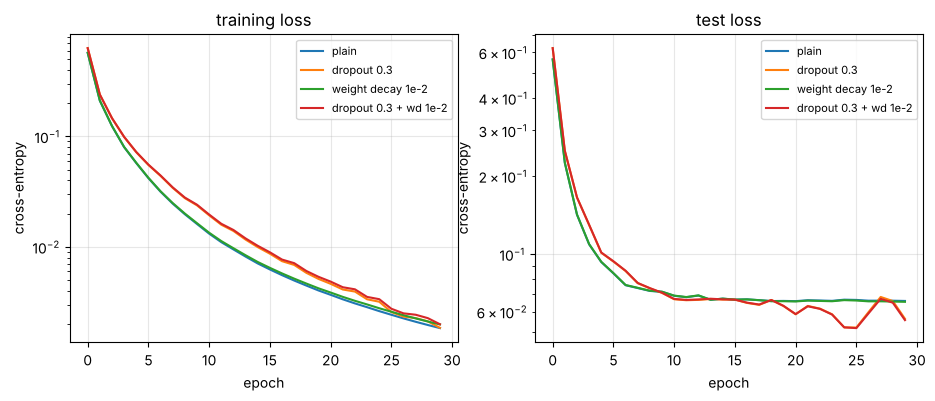

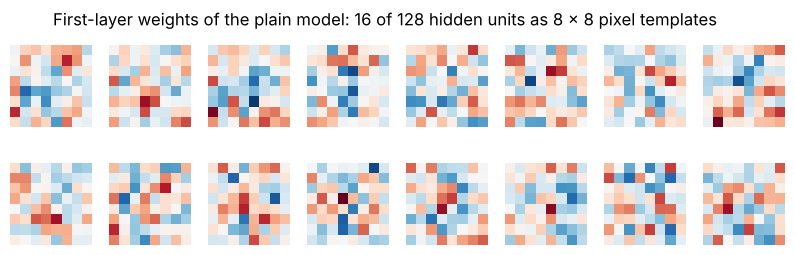

The confidence intervals of the four configurations overlap: on 360 test images the differences are not resolvable.


In [21]:
from sklearn.datasets import load_digits

def softmax_ce(Z, y):
    n = Z.shape[0]
    logp = log_softmax(Z)
    loss = -logp[np.arange(n), y].mean()
    G = np.exp(logp); G[np.arange(n), y] -= 1.0
    return loss, G / n

class Dropout:
    def __init__(self, p, rng):
        self.p, self.rng, self.training = p, rng, True
    def forward(self, A):
        A_out, self.mask = dropout_forward(A, self.p, self.rng, self.training)
        return A_out
    def backward(self, G): return dropout_backward(G, self.mask)
    def params(self): return []
    def grads(self):  return []

class Adam:
    def __init__(self, model, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.0):
        self.model, self.lr, self.b1, self.b2, self.eps, self.wd = model, lr, beta1, beta2, eps, weight_decay
        self.m = [np.zeros_like(p) for p in model.params()]; self.v = [np.zeros_like(p) for p in model.params()]; self.t = 0
    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(zip(self.model.params(), self.model.grads())):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g
            m_hat = self.m[i] / (1 - self.b1 ** self.t); v_hat = self.v[i] / (1 - self.b2 ** self.t)
            p -= self.lr * (m_hat / (np.sqrt(v_hat) + self.eps) + self.wd * p)

def set_training(model, flag):
    for layer in model.layers:
        if hasattr(layer, "training"):
            layer.training = flag

# data: standardise with training statistics, 80/20 split
digits = load_digits(); X_all, y_all = digits.data, digits.target
split = np.random.default_rng(16).permutation(len(X_all)); n_tr = int(0.8 * len(X_all))
X_tr, y_tr = X_all[split[:n_tr]], y_all[split[:n_tr]]; X_te, y_te = X_all[split[n_tr:]], y_all[split[n_tr:]]
mu, sd = X_tr.mean(axis=0), X_tr.std(axis=0); sd[sd == 0] = 1.0
X_tr = (X_tr - mu) / sd; X_te = (X_te - mu) / sd

def build(p_drop, seed):
    r = np.random.default_rng(seed)
    layers = [Dense(64, 128, rng=r), ReLU()]
    if p_drop > 0:
        layers.append(Dropout(p_drop, rng=r))
    layers.append(Dense(128, 10, scale=0.01, rng=r))
    return MLP(layers)

def fit(model, weight_decay, epochs=30, batch_size=64, lr=3e-3, seed=1):
    r = np.random.default_rng(seed); opt = Adam(model, lr=lr, weight_decay=weight_decay)
    tr_loss, te_loss = [], []
    for epoch in range(epochs):
        set_training(model, True)
        order = r.permutation(len(X_tr))
        for s in range(0, len(X_tr), batch_size):
            idx = order[s:s + batch_size]
            loss, G = softmax_ce(model.forward(X_tr[idx]), y_tr[idx]); model.backward(G); opt.step()
        set_training(model, False)
        tr_loss.append(softmax_ce(model.forward(X_tr), y_tr)[0]); te_loss.append(softmax_ce(model.forward(X_te), y_te)[0])
    return np.array(tr_loss), np.array(te_loss)

def bootstrap_ci(correct, n_boot=2000, seed=0):
    r = np.random.default_rng(seed)
    accs = np.array([r.choice(correct, size=len(correct), replace=True).mean() for _ in range(n_boot)])
    return correct.mean(), np.percentile(accs, 2.5), np.percentile(accs, 97.5)

# gradient check before training (small batch, float64)
probe = build(0.0, 0); rel = grad_check(probe, softmax_ce, X_tr[:5], y_tr[:5])
print(f"gradient check of the untrained model: relative error {rel:.1e}")

configs = {"plain": (0.0, 0.0), "dropout 0.3": (0.3, 0.0), "weight decay 1e-2": (0.0, 1e-2), "dropout 0.3 + wd 1e-2": (0.3, 1e-2)}
results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (p_drop, wd) in configs.items():
    model = build(p_drop, seed=0)
    tr, te = fit(model, wd)
    correct = (model.forward(X_te).argmax(axis=1) == y_te).astype(float)
    acc, lo, hi = bootstrap_ci(correct)
    results[name] = (acc, lo, hi, model)
    axes[0].plot(tr, label=name); axes[1].plot(te, label=name)
    print(f"{name:24s} test accuracy {acc:.4f}   95% bootstrap CI [{lo:.4f}, {hi:.4f}]   final test loss {te[-1]:.4f}   final train loss {tr[-1]:.4f}")
axes[0].set_title("training loss"); axes[1].set_title("test loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.set_yscale("log"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

# first-layer weights as 8 x 8 images
W1 = results["plain"][3].layers[0].W           # (64, 128): column j is hidden unit j's template over the 64 pixels
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(W1[:, j].reshape(8, 8), cmap="RdBu", vmin=-np.abs(W1[:, :16]).max(), vmax=np.abs(W1[:, :16]).max()); ax.axis("off")
fig.suptitle("First-layer weights of the plain model: 16 of 128 hidden units as 8 x 8 pixel templates"); plt.show()
print("The confidence intervals of the four configurations overlap: on 360 test images the differences are not resolvable.")

## Score

In [22]:
summary()


Score: 65/65 checks passed  🎉
